# F2 · FLIR ADAS v2 dataset statistics

Visual summary of the report written by `projects/data_stats/stats.py`
(spec `spec/2026-10-08-flir-readers-class-mapping`, results note `stats.md`).

The notebook only **reads** `flir_stats.json` from a stats run dir under
`$IRWM_OUTPUT_ROOT/data_stats/<date>/<time>/`. By default it picks the most recent run;
set `RUN_DIR` to pin one. Setup: `uv sync --group notebook`.

In [79]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from irwm.data.classes import CLASS_NAMES
from irwm.utils.paths import load_env, output_root

load_env()

RUN_DIR: Path | None = None  # e.g. output_root() / "data_stats/2026-10-09/13-25-56"

if RUN_DIR is None:
    runs = sorted((output_root() / "data_stats").glob("*/*/flir_stats.json"))
    assert runs, f"no flir_stats.json under {output_root() / 'data_stats'}; run projects/data_stats/stats.py"
    RUN_DIR = runs[-1].parent
stats = json.loads((RUN_DIR / "flir_stats.json").read_text())
print(f"run dir: {RUN_DIR}")
print(f"commit:  {stats['git']['commit']}  dirty={stats['git']['dirty']}")
print(f"root:    {stats['config']['flir']['root']}")

run dir: /home/leonardo.ulloa/irwm/outputs/data_stats/2026-10-09/13-27-02
commit:  a4d65ef0724e29ee8a9fa2318fb56831df8e22b4  dirty=False
root:    /home/leonardo.ulloa/projects/data/teledyne_flir_adas_v2


In [80]:
# Plot style: two series (RGB, thermal) in fixed categorical slots 1-2; ignored classes in gray.
MOD_COLOR = {"rgb": "#2a78d6", "thermal": "#eb6834"}
MOD_LABEL = {"rgb": "RGB", "thermal": "Thermal"}
IGNORE_GRAY = "#a3a29c"
SPLITS = ["train", "val", "test"]
MODS = ["rgb", "thermal"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def table(header, rows):
    fmt = lambda v: f"{v:.2f}" if isinstance(v, float) else ("–" if v is None else str(v))
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


classes = stats["classes"]
row = {(c["name"], c["modality"], c["split"]): c for c in classes}
raw_names = sorted({c["name"] for c in classes},
                   key=lambda n: -sum(row[(n, m, s)]["boxes"] for m in MODS for s in SPLITS))

## 1. Images per split
Frames, frames without any annotation, and frames without any of the 6 kept classes.

In [81]:
table(["split", "images", "no annotation", "no kept box"],
      [[k, v["n_images"], v["no_annotation"], v["no_kept_box"]] for k, v in stats["images"].items()])
table(["split", "frame sizes (W×H: n)"],
      [[k, ", ".join(f"{s}: {n}" for s, n in v["sizes"].items())] for k, v in stats["images"].items()])

| split | images | no annotation | no kept box |
|---|---|---|---|
| rgb/train | 10318 | 265 | 280 |
| rgb/val | 1085 | 16 | 16 |
| rgb/test | 3749 | 0 | 98 |
| thermal/train | 10742 | 264 | 280 |
| thermal/val | 1144 | 16 | 19 |
| thermal/test | 3749 | 256 | 256 |

| split | frame sizes (W×H: n) |
|---|---|
| rgb/train | 1800x1600: 5015, 1224x1024: 1992, 2048x1536: 1886, 1280x1024: 1378, 720x480: 47 |
| rgb/val | 1800x1600: 879, 1224x1024: 183, 1280x1024: 23 |
| rgb/test | 1224x1024: 2151, 1024x768: 1598 |
| thermal/train | 640x512: 10742 |
| thermal/val | 640x512: 1144 |
| thermal/test | 640x512: 3749 |

## 2. All 16 raw FLIR classes — the imbalance study
Box counts on a log scale, summed over train + val + test. The 6 selected classes are
colored; the 10 ignored classes (ignore regions in training and evaluation) are gray.

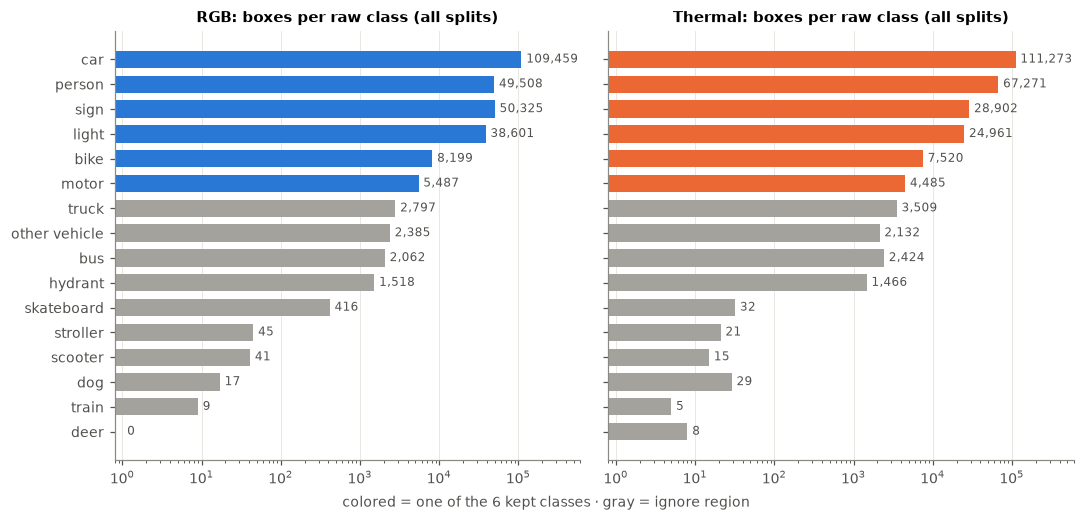

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
y = np.arange(len(raw_names))[::-1]
for ax, m in zip(axes, MODS):
    totals = [sum(row[(n, m, s)]["boxes"] for s in SPLITS) for n in raw_names]
    colors = [MOD_COLOR[m] if row[(n, m, "train")]["selected"] else IGNORE_GRAY for n in raw_names]
    ax.barh(y, [max(t, 0.8) for t in totals], height=0.7, color=colors)
    for yi, t in zip(y, totals):
        ax.text(max(t, 1) * 1.15, yi, f"{t:,}", va="center", fontsize=8, color="#52514e")
    ax.set_xscale("log")
    ax.set_xlim(0.8, 6e5)
    ax.set_title(f"{MOD_LABEL[m]}: boxes per raw class (all splits)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, raw_names)
fig.text(0.5, -0.01, "colored = one of the 6 kept classes · gray = ignore region", ha="center", color="#52514e")
fig.tight_layout()

In [83]:
flag_rows = []
for n in raw_names:
    r = row[(n, "rgb", "train")]
    flag_rows.append([n, r["category_id"], "yes" if r["selected"] else "", "yes" if r["coco80"] else "",
                      "yes" if r["absent_val"] or row[(n, "thermal", "val")]["absent_val"] else "",
                      "yes" if r["absent_test"] or row[(n, "thermal", "test")]["absent_test"] else "",
                      ", ".join(f"{m}/{s}" for m in MODS for s in SPLITS if row[(n, m, s)]["underrepresented"])])
table(["class", "FLIR id", "selected", "in COCO-80", "absent in val (any mod.)",
       "absent in test (any mod.)", "under-represented in"], flag_rows)

| class | FLIR id | selected | in COCO-80 | absent in val (any mod.) | absent in test (any mod.) | under-represented in |
|---|---|---|---|---|---|---|
| car | 3 | yes | yes |  |  |  |
| person | 1 | yes | yes |  |  |  |
| sign | 12 | yes |  |  |  |  |
| light | 10 | yes | yes |  |  |  |
| bike | 2 | yes | yes |  |  | rgb/test, thermal/test |
| motor | 4 | yes | yes |  |  | rgb/val, thermal/train, thermal/val |
| truck | 8 |  | yes |  |  | rgb/train, rgb/val, thermal/train, thermal/val |
| other vehicle | 79 |  |  |  |  | rgb/train, rgb/val, thermal/train, thermal/val |
| bus | 6 |  | yes |  | yes | rgb/test, thermal/test |
| hydrant | 11 |  | yes |  |  | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| skateboard | 37 |  | yes |  | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| stroller | 73 |  |  |  | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| scooter | 75 |  |  | yes | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| dog | 17 |  | yes | yes |  | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| train | 7 |  | yes | yes | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |
| deer | 18 |  |  | yes | yes | rgb/train, rgb/val, rgb/test, thermal/train, thermal/val, thermal/test |

## 3. The 6 kept classes, per split
Kept boxes per class and split. Each panel has its own scale: train is ~10× val. The number
on each bar is that class's share (%) of **all** boxes (kept + ignored) of its modality and split,
e.g. car = 42.1 on the RGB train bar means 42.1% of the RGB train boxes are cars.
In the table the 6 kept classes are in bold; ignored classes with more than 500 boxes
(summed over all modalities and splits) get their own row, and the rest are summed in
the last row.

| class | RGB train | RGB val | RGB test | Thermal train | Thermal val | Thermal test |
|---|---|---|---|---|---|---|
| **person** ✓ | **35,007** | **3,223** | **11,278** | **50,478** | **4,470** | **12,323** |
| **bike** ✓ | **7,560** | **193** | **446** | **7,237** | **170** | **113** |
| **car** ✓ | **71,281** | **7,285** | **30,893** | **73,623** | **7,133** | **30,517** |
| **motor** ✓ | **1,837** | **77** | **3,573** | **1,116** | **55** | **3,314** |
| **light** ✓ | **18,640** | **2,143** | **17,818** | **16,198** | **2,005** | **6,758** |
| **sign** ✓ | **29,531** | **3,581** | **17,213** | **20,770** | **2,472** | **5,660** |
| truck *(ignore)* | 1,251 | 47 | 1,499 | 829 | 46 | 2,634 |
| other vehicle *(ignore)* | 698 | 40 | 1,647 | 1,373 | 63 | 696 |
| bus *(ignore)* | 1,879 | 183 | 0 | 2,245 | 179 | 0 |
| hydrant *(ignore)* | 990 | 126 | 402 | 1,095 | 94 | 277 |
| other ignored *(6 classes)* | 500 | 11 | 17 | 76 | 9 | 25 |

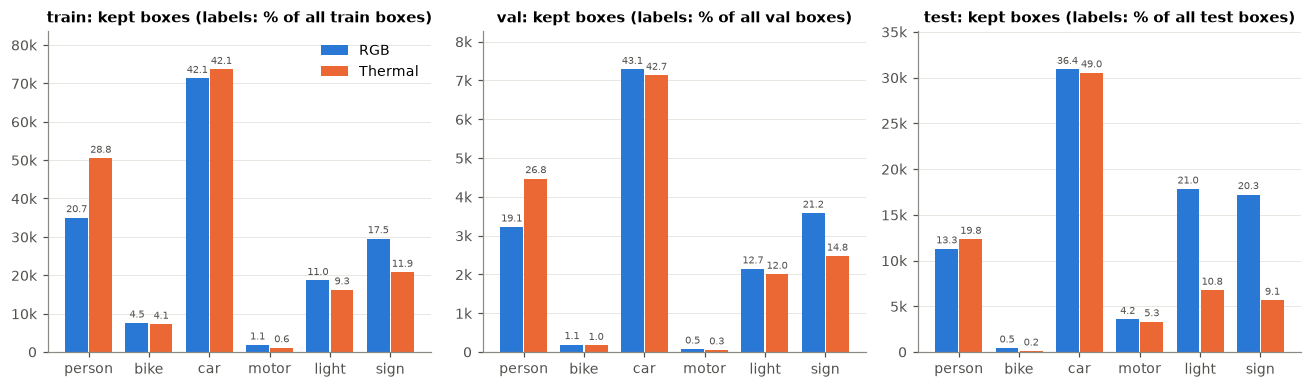

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
x = np.arange(len(CLASS_NAMES))
w = 0.38
for ax, s in zip(axes, SPLITS):
    for i, m in enumerate(MODS):
        sel = stats["selected"][f"{m}/{s}"]
        vals = [sel["kept"][c] for c in CLASS_NAMES]
        total = sel["total_kept"] + sel["total_ignore"]
        # 2px-ish gap between the paired bars
        bars = ax.bar(x + (i - 0.5) * (w + 0.02), vals, width=w, color=MOD_COLOR[m], label=MOD_LABEL[m])
        ax.bar_label(bars, [f"{100 * v / total:.1f}" for v in vals], padding=2, fontsize=6.5, color="#52514e")
    ax.set_xticks(x, CLASS_NAMES)
    ax.set_title(f"{s}: kept boxes (labels: % of all {s} boxes)")
    ax.set_ylim(top=ax.get_ylim()[1] * 1.08)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:g}k" if v >= 1000 else f"{v:g}"))
axes[0].legend(loc="upper right")
fig.tight_layout()

MIN_BOXES_OWN_ROW = 500
cols = [(m, s) for m in MODS for s in SPLITS]
big_ignored = [n for n in raw_names if not row[(n, "rgb", "train")]["selected"]
               and sum(row[(n, m, s)]["boxes"] for m, s in cols) > MIN_BOXES_OWN_ROW]
rest = [stats["selected"][f"{m}/{s}"]["total_ignore"] - sum(row[(n, m, s)]["boxes"] for n in big_ignored)
        for m, s in cols]
table(["class", *[f"{MOD_LABEL[m]} {s}" for m, s in cols]],
      [[f"**{c}** ✓", *[f"**{stats['selected'][f'{m}/{s}']['kept'][c]:,}**" for m, s in cols]] for c in CLASS_NAMES]
      + [[f"{n} *(ignore)*", *[f"{row[(n, m, s)]['boxes']:,}" for m, s in cols]] for n in big_ignored]
      + [[f"other ignored *({len(raw_names) - len(CLASS_NAMES) - len(big_ignored)} classes)*", *[f"{v:,}" for v in rest]]])

## 4. Modality asymmetry on the test split
Thermal ÷ RGB box count per kept class. The test frames are time-synced pairs, so a ratio
far from 1 means the two modalities were annotated differently, not that the scenes differ.

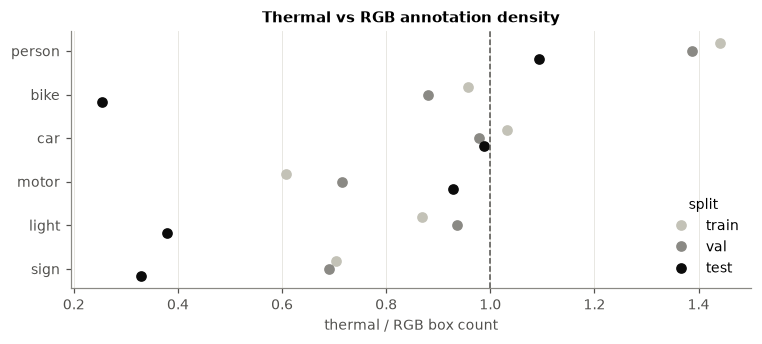

In [85]:
fig, ax = plt.subplots(figsize=(7, 3.2))
comp = stats["modality_comparison"]
for j, s in enumerate(SPLITS):
    vals = [comp[c][s] for c in CLASS_NAMES]
    ax.plot(vals, np.arange(len(CLASS_NAMES))[::-1] + (1 - j) * 0.18, "o", ms=6,
            color=["#c3c2b7", "#8a8984", "#0b0b0b"][j], label=s)
ax.axvline(1, color="#52514e", lw=1, ls="--")
ax.set_yticks(np.arange(len(CLASS_NAMES))[::-1], CLASS_NAMES)
ax.set_xlabel("thermal / RGB box count")
ax.set_title("Thermal vs RGB annotation density")
ax.legend(loc="lower right", title="split")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## 5. Object sizes (normalised to 640×512)
Share of kept boxes in the COCO buckets S (< 32²), M (< 96²) and L, after rescaling every
area to a 640×512 frame. Most objects are small, which matters for detection on a 14-px
patch grid (Roadmap R3).

| modality/split | S | M | L |
|---|---|---|---|
| rgb/train | 125708 | 32608 | 5540 |
| rgb/val | 13499 | 2476 | 527 |
| rgb/test | 72480 | 7100 | 1641 |
| thermal/train | 126045 | 36650 | 6727 |
| thermal/val | 12218 | 3395 | 692 |
| thermal/test | 50312 | 7162 | 1211 |

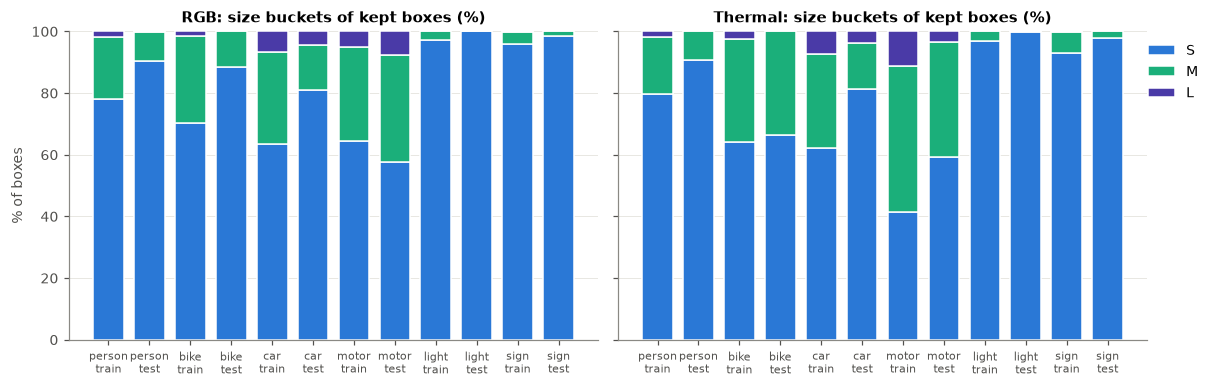

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bucket_color = {"S": "#2a78d6", "M": "#1baf7a", "L": "#4a3aa7"}
for ax, m in zip(axes, MODS):
    labels, frac = [], {b: [] for b in "SML"}
    for c in CLASS_NAMES:
        for s in ("train", "test"):
            d = row[(c, m, s)]["size_normalised"]
            tot = sum(d.values()) or 1
            labels.append(f"{c}\n{s}")
            for b in "SML":
                frac[b].append(100 * d[b] / tot)
    xx = np.arange(len(labels))
    bottom = np.zeros(len(labels))
    for b in "SML":
        ax.bar(xx, frac[b], bottom=bottom, width=0.75, color=bucket_color[b], label=b,
               edgecolor="white", linewidth=1)
        bottom += frac[b]
    ax.set_xticks(xx, labels, fontsize=7)
    ax.set_title(f"{MOD_LABEL[m]}: size buckets of kept boxes (%)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of boxes")
axes[1].legend(loc="upper right", bbox_to_anchor=(1.12, 1))
fig.tight_layout()

table(["modality/split", "S", "M", "L"],
      [[f"{m}/{s}", *[sum(row[(c, m, s)]["size_normalised"][b] for c in CLASS_NAMES) for b in "SML"]]
       for m in MODS for s in SPLITS])

### 5.1 What S/M/L look like on a real frame
A random time-synced test pair (RGB left, thermal right) with every kept box colored by its
bucket, computed on the 640×512-normalised area as in the plot above. Ignore regions are dashed gray.
The dotted squares in the bottom-left corner mark the thresholds in this frame's own pixels:
the small one is 32² (S|M), the large one is 96² (M|L). An object has to cover about
2.8% of the frame (96²/(640·512)) to count as L, so on a forward-facing car camera only very close objects
reach it. Set `SEED` to pin a frame.

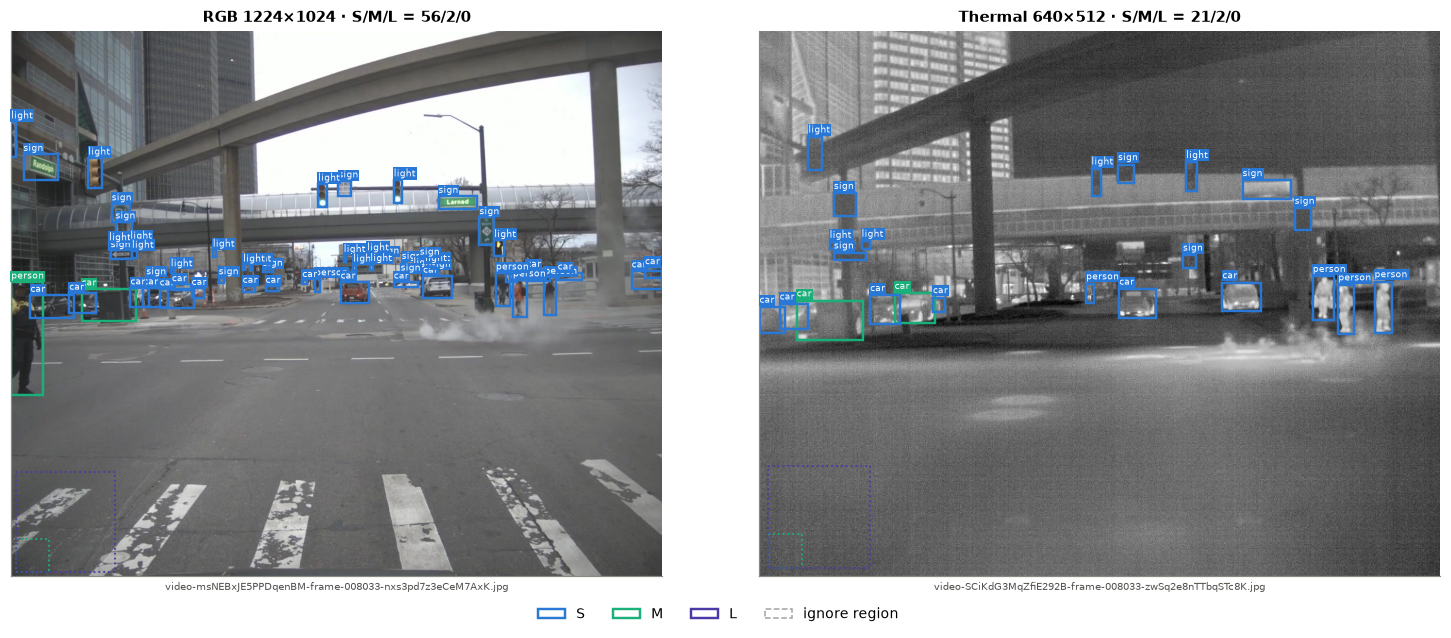

In [87]:
from matplotlib.patches import Rectangle
from PIL import Image

from irwm.data.classes import normalised_area, size_bucket
from irwm.data.flir import FlirSplit, load_rgb_thermal_map

SEED = None  # set an int to pin the frame; None draws a new one each run
MIN_BOXES = 5  # skip near-empty frames

test = {m: FlirSplit.load(m, "test", FLIR_ROOT) for m in MODS}
by_name = {m: {Path(r.file_name).name: r for r in test[m]} for m in MODS}
rgb_to_th = load_rgb_thermal_map(FLIR_ROOT)
pairs = [(r, by_name["thermal"][rgb_to_th[n]]) for n, r in by_name["rgb"].items()
         if rgb_to_th.get(n) in by_name["thermal"] and len(r.boxes) >= MIN_BOXES]
rng = np.random.default_rng(SEED)
pair = dict(zip(MODS, pairs[rng.integers(len(pairs))]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, m in zip(axes, MODS):
    r = pair[m]
    ax.imshow(np.asarray(Image.open(r.path)), cmap="gray")
    for x, y, w, h in r.ignore_boxes:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=IGNORE_GRAY, lw=1, ls="--"))
    for (x, y, w, h), lab in zip(r.boxes, r.labels):
        b = size_bucket(normalised_area(w, h, r.width, r.height))
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=bucket_color[b], lw=1.6))
        ax.text(x, y - 2, CLASS_NAMES[lab], color="white", fontsize=6, va="bottom",
                bbox=dict(fc=bucket_color[b], ec="none", pad=0.6))
    # Reference squares at the S/M (32²) and M/L (96²) thresholds, in this frame's native pixels.
    s = np.sqrt(r.width * r.height / (640 * 512))
    for side, b in ((32, "S"), (96, "M")):
        ax.add_patch(Rectangle((8, r.height - 8 - side * s), side * s, side * s, fill=False,
                               ec=bucket_color["L" if b == "M" else "M"], lw=1.2, ls=":"))
    n = {b: sum(size_bucket(normalised_area(w, h, r.width, r.height)) == b for _, _, w, h in r.boxes) for b in "SML"}
    ax.set_title(f"{MOD_LABEL[m]} {r.width}×{r.height} · S/M/L = {n['S']}/{n['M']}/{n['L']}")
    ax.set_xlabel(r.file_name.split("/")[-1], fontsize=6.5)
    ax.set_xticks([]), ax.set_yticks([])
    ax.grid(False)
handles = [Rectangle((0, 0), 1, 1, fill=False, ec=bucket_color[b], lw=1.6, label=b) for b in "SML"]
handles.append(Rectangle((0, 0), 1, 1, fill=False, ec=IGNORE_GRAY, ls="--", label="ignore region"))
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.04, 1, 1))

## 6. Test video sequences
Each bar is one contiguous run of frames on the `frame_index` axis; white space between runs
is a gap. These are the 8 sequences per modality that F3 cuts into clips.

| modality | video_id | frames | min | max | gaps (sizes) | tags |
|---|---|---|---|---|---|---|
| rgb | BzZspxAweF8AnKhWK | 338 | 745 | 1082 | – | fog, night, residential |
| rgb | FkqCGijjAKpABetZZ | 226 | 0 | 225 | – |  |
| rgb | PGdt7pJChnKoJDt35 | 208 | 368 | 575 | – | fog, night, residential |
| rgb | RMxN6a4CcCeLGu4tA | 1033 | 0 | 1479 | 271, 178 |  |
| rgb | YnfPeH8i2uBWmsSd2 | 540 | 300 | 839 | – | night, rain |
| rgb | dvZBYnphN2BwdMKBc | 565 | 0 | 564 | – |  |
| rgb | hnbGXq3nNPjBbc7CL | 411 | 99 | 509 | – | rain, night |
| rgb | msNEBxJE5PPDqenBM | 428 | 6393 | 8072 | 1253 |  |
| thermal | 4FRnNpmSmwktFJKjg | 338 | 745 | 1082 | – | fog, night, residential |
| thermal | 5RSrbWYu9eokv5bvR | 411 | 99 | 509 | – | night, rain |
| thermal | 6tLtjdkv5K5BuhB37 | 226 | 0 | 225 | – |  |
| thermal | SCiKdG3MqZfiE292B | 428 | 6393 | 8072 | 1253 | day |
| thermal | ZAtDSNuZZjkZFvMAo | 1033 | 0 | 1479 | 271, 178 |  |
| thermal | ePoikf5LyTTfqchga | 540 | 300 | 839 | – | rain, night |
| thermal | t3f7QC8hZr6zYXpEZ | 565 | 0 | 564 | – |  |
| thermal | vbrSzr4vFTm5QwuGH | 208 | 368 | 575 | – | fog, night, residential |

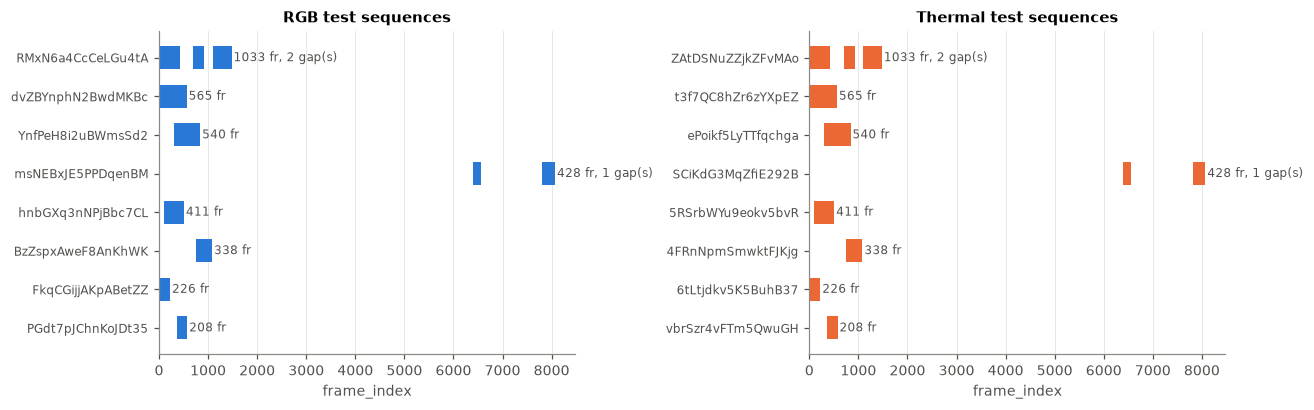

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m in zip(axes, MODS):
    seqs = sorted(stats["sequences"][m], key=lambda q: -q["n_frames"])
    for yi, q in enumerate(seqs):
        start = q["frame_min"]
        for seg, gap in zip(q["segments"], q["gap_sizes"] + [0]):
            ax.barh(yi, seg, left=start, height=0.6, color=MOD_COLOR[m])
            start += seg - 1 + gap
        ax.text(q["frame_max"] + 40, yi, f"{q['n_frames']} fr" + (f", {q['n_gaps']} gap(s)" if q["n_gaps"] else ""),
                va="center", fontsize=8, color="#52514e")
    ax.set_yticks(range(len(seqs)), [q["video_id"] for q in seqs], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("frame_index")
    ax.set_title(f"{MOD_LABEL[m]} test sequences")
    ax.grid(axis="y", visible=False)
fig.tight_layout()

table(["modality", "video_id", "frames", "min", "max", "gaps (sizes)", "tags"],
      [[m, q["video_id"], q["n_frames"], q["frame_min"], q["frame_max"],
        ", ".join(map(str, q["gap_sizes"])) or "–",
        ", ".join(t for t in q["tags"] if t in {"day", "night", "fog", "rain", "city", "highway", "residential"})]
       for m in MODS for q in stats["sequences"][m]])

### 6.1 Segment lengths
Length of every contiguous run of frames (a *segment*) in the test split. Clips cannot span a
`frame_index` gap, so segments, not videos, are what F3 has to work with. A video with gaps
shows up as several segments (`#1`, `#2`, …). The three axes give each length in frames
(bottom), in seconds at the README's 30 FPS (top) and as frames / 5, i.e. roughly the number of
steps at the F3 stride of 5 (lower axis). The dashed line is one 4 + 6-step clip
(46 frames at stride 5). If RGB and thermal segments are identical (the test frames are
time-synced pairs) only one panel is drawn.

RGB and thermal segment lengths identical: True


/tmp/ipykernel_33639/1233257368.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right", fontsize=7.5)


| modality | segments | frames | min | median | max | seconds | frames / 5 |
|---|---|---|---|---|---|---|---|
| rgb | 11 | 3749 | 164 | 338 | 565 | 124.97 | 749.80 |
| thermal | 11 | 3749 | 164 | 338 | 565 | 124.97 | 749.80 |

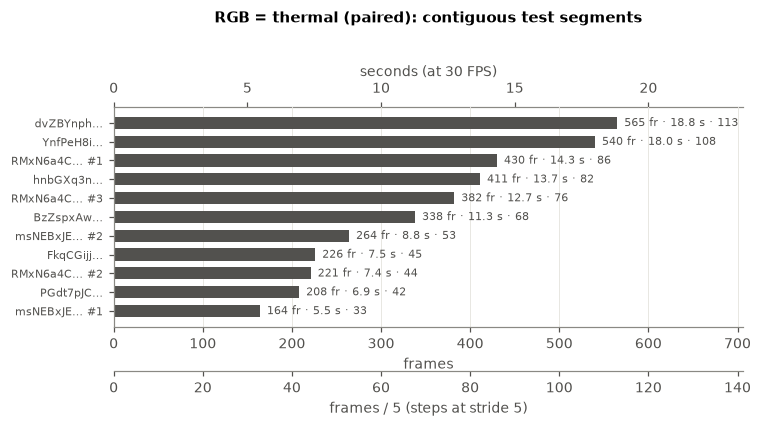

In [95]:
FPS = 30  # README value; the test split has no timestamps to check it (F2)
STRIDE = 5  # frame stride from F1 (Roadmap F3)
CLIP_STEPS = 4 + 6  # context + future
min_clip_frames = (CLIP_STEPS - 1) * STRIDE + 1

segs = {m: sorted(((n, q["video_id"], k) for q in stats["sequences"][m]
                   for k, n in enumerate(q["segments"], 1)), reverse=True) for m in MODS}
same = [n for n, *_ in segs["rgb"]] == [n for n, *_ in segs["thermal"]]
print(f"RGB and thermal segment lengths identical: {same}")
modalities = ["rgb"] if same else MODS

fig, axes = plt.subplots(1, len(modalities), figsize=(7 * len(modalities), 4.2), squeeze=False)
for ax, m in zip(axes[0], modalities):
    lengths = np.array([n for n, *_ in segs[m]])
    yy = np.arange(len(lengths))
    multi = {v for _, v, k in segs[m] if k > 1}
    ax.barh(yy, lengths, height=0.65, color=MOD_COLOR[m] if not same else "#52514e")
    ax.set_yticks(yy, [f"{v[:8]}… #{k}" if v in multi else f"{v[:8]}…" for _, v, k in segs[m]], fontsize=7.5)
    ax.invert_yaxis()
    for yi, n in zip(yy, lengths):
        ax.text(n + 8, yi, f"{n} fr · {n / FPS:.1f} s · {n / STRIDE:.0f}", va="center", fontsize=7, color="#52514e")
    #ax.axvline(min_clip_frames, color="#e34948", lw=1, ls="--",
    #           label=f"one clip ({CLIP_STEPS} steps at stride {STRIDE}) = {min_clip_frames} fr")
    ax.legend(loc="lower right", fontsize=7.5)
    ax.set_xlim(0, lengths.max() * 1.25)
    ax.set_xlabel("frames")
    top = ax.secondary_xaxis("top", functions=(lambda f: f / FPS, lambda s: s * FPS))
    top.set_xlabel(f"seconds (at {FPS} FPS)")
    low = ax.secondary_xaxis(-0.2, functions=(lambda f: f / STRIDE, lambda k: k * STRIDE))
    low.set_xlabel(f"frames / {STRIDE} (steps at stride {STRIDE})")
    ax.set_title(("RGB = thermal (paired)" if same else MOD_LABEL[m]) + ": contiguous test segments", pad=28)
    ax.grid(axis="y", visible=False)
fig.tight_layout()

table(["modality", "segments", "frames", "min", "median", "max", "seconds", f"frames / {STRIDE}"],
      [[m, len(segs[m]), sum(n for n, *_ in segs[m]), min(n for n, *_ in segs[m]),
        int(np.median([n for n, *_ in segs[m]])), max(n for n, *_ in segs[m]),
        sum(n for n, *_ in segs[m]) / FPS, sum(n for n, *_ in segs[m]) / STRIDE] for m in MODS])

## 7. File integrity
Every JPEG header compared with `coco.json` (size) and with the expected PIL mode
(`L` for thermal, `RGB` for RGB), plus files in `data/` that `coco.json` does not list.

In [90]:
fi = stats.get("file_integrity")
if fi is None:
    print("not checked (run with check_files=true)")
else:
    table(["split", "checked", "size mismatches", "mode mismatches", "orphans"],
          [[k, v["n_checked"], len(v["size_mismatches"]), len(v["mode_mismatches"]), len(v["orphans"])]
           for k, v in fi.items()])
    for v in fi.values():
        for o in v["orphans"]:
            print("orphan:", o)

| split | checked | size mismatches | mode mismatches | orphans |
|---|---|---|---|---|
| rgb/train | 10318 | 0 | 0 | 1 |
| rgb/val | 1085 | 0 | 0 | 0 |
| rgb/test | 3749 | 0 | 0 | 0 |
| thermal/train | 10742 | 0 | 0 | 0 |
| thermal/val | 1144 | 0 | 0 | 0 |
| thermal/test | 3749 | 0 | 0 | 0 |

orphan: images_rgb_train/data/video-GNhgScttHWdvYkPke-frame-000000-JQkmaAp6qjNJu4w5H.jpg


## 8. Domain distribution (time of day, weather, scene)
Share of frames per domain, for each modality and split. Unlike the sections above, this one
reads the dataset directly (not `flir_stats.json`), from two sources:

- **frame label**: `extra_info` of each image in `coco.json` (`hours`, `weather`, `scene`).
  Present on train/val only, and sparse for thermal (e.g. `hours` on ~30% of thermal train).
- **video tag**: the free-form tags of the frame's video in `index.json`, mapped to the same
  vocabulary (e.g. `dark` → night, `wet` → rain, `freeway` → highway). This is the only source
  for test. A video whose tags point to two values of one facet is counted as *mixed*.

The frame label wins when both exist. `partly_cloudy` and `overcast` are merged into *cloudy*;
`tunnel`, `gas_station` and the `rural` tag fold into *other*.

In [91]:
from collections import Counter

from irwm.data.flir import split_dir

FLIR_ROOT = Path(stats["config"]["flir"]["root"])
FACETS = {
    "time": ["day", "dawn/dusk", "night"],
    "weather": ["clear", "cloudy", "rain", "fog", "snow"],
    "scene": ["city_street", "residential", "highway", "parking_lot", "other"],
}
COCO_KEY = {"time": "hours", "weather": "weather", "scene": "scene"}
# coco.json extra_info value -> displayed domain
FRAME_TO_DOMAIN = {
    "weather": {"partly_cloudy": "cloudy", "overcast": "cloudy", "rainy": "rain", "foggy": "fog", "snowy": "snow"},
    "scene": {"tunnel": "other", "gas_station": "other"},
}
# index.json video tag -> displayed domain
TAG_TO_DOMAIN = {
    "time": {"day": "day", "night": "night", "dark": "night", "dawn": "dawn/dusk", "dusk": "dawn/dusk", "sunset": "dawn/dusk"},
    "weather": {"cloudy": "cloudy", "rain": "rain", "wet": "rain", "fog": "fog"},
    "scene": {"city": "city_street", "urban": "city_street", "highway": "highway", "freeway": "highway",
              "residential": "residential", "village": "residential", "parking": "parking_lot", "rural": "other"},
}


def frame_domains(m, s):
    """One dict per frame: facet -> (domain, source), source in {frame, video, none}; plus video_id."""
    d = split_dir(m, s, FLIR_ROOT)
    images = json.loads((d / "coco.json").read_text())["images"]
    video_tags = {v["id"]: v.get("tags") or [] for v in json.loads((d / "index.json").read_text())["videos"]}
    out = []
    for im in images:
        ei = im.get("extra_info", {})
        tags = video_tags.get(ei["video_id"], [])
        rec = {"video_id": ei["video_id"]}
        for f in FACETS:
            if COCO_KEY[f] in ei:
                v = ei[COCO_KEY[f]]
                rec[f] = (FRAME_TO_DOMAIN.get(f, {}).get(v, v), "frame")
                continue
            vals = {TAG_TO_DOMAIN[f][t] for t in tags if t in TAG_TO_DOMAIN[f]}
            if not vals:
                rec[f] = ("unknown", "none")
            else:
                rec[f] = (vals.pop() if len(vals) == 1 else "mixed", "video")
        out.append(rec)
    return out


domains = {(m, s): frame_domains(m, s) for m in MODS for s in SPLITS}  # reads the 6 index.json (~400 MB)
unexpected = {r[f][0] for recs in domains.values() for r in recs for f in FACETS} \
    - {d for v in FACETS.values() for d in v} - {"mixed", "unknown"}
assert not unexpected, f"unmapped domain values: {unexpected}"

### 8a. Where the labels come from
Share of frames whose domain comes from the frame label, from a video tag, or from neither.

In [92]:
table(["modality/split", "frames", *[f"{f}: frame / video / none (%)" for f in FACETS]],
      [[f"{m}/{s}", len(recs),
        *[" / ".join(f"{100 * Counter(r[f][1] for r in recs)[src] / len(recs):.0f}"
                     for src in ("frame", "video", "none")) for f in FACETS]]
       for (m, s), recs in domains.items()])

| modality/split | frames | time: frame / video / none (%) | weather: frame / video / none (%) | scene: frame / video / none (%) |
|---|---|---|---|---|
| rgb/train | 10318 | 99 / 0 / 0 | 66 / 2 / 32 | 100 / 0 / 0 |
| rgb/val | 1085 | 99 / 1 / 0 | 67 / 2 / 32 | 100 / 0 / 0 |
| rgb/test | 3749 | 0 / 67 / 33 | 0 / 67 / 33 | 0 / 36 / 64 |
| thermal/train | 10742 | 29 / 69 / 2 | 10 / 12 / 78 | 100 / 0 / 0 |
| thermal/val | 1144 | 21 / 78 / 1 | 11 / 6 / 83 | 99 / 0 / 1 |
| thermal/test | 3749 | 0 / 79 / 21 | 0 / 67 / 33 | 0 / 36 / 64 |

### 8b. Domain shares
One stacked bar per modality/split; gray is *unknown* (no label from either source), hatched gray
is *mixed* (conflicting video tags). Test is only 8 videos per modality, so its shares move in
large steps and come from video tags alone.

| **time**: modality/split | day | dawn/dusk | night | mixed | unknown |
|---|---|---|---|---|---|
| rgb/train | 6232 | 417 | 3665 | 2 | 2 |
| rgb/val | 710 | 1 | 374 | 0 | 0 |
| rgb/test | 0 | 1033 | 1497 | 0 | 1219 |
| thermal/train | 6285 | 98 | 3587 | 596 | 176 |
| thermal/val | 775 | 0 | 354 | 0 | 15 |
| thermal/test | 428 | 1033 | 1497 | 0 | 791 |

| **weather**: modality/split | clear | cloudy | rain | fog | snow | mixed | unknown |
|---|---|---|---|---|---|---|---|
| rgb/train | 4515 | 2377 | 112 | 7 | 0 | 2 | 3305 |
| rgb/val | 559 | 173 | 1 | 9 | 0 | 0 | 343 |
| rgb/test | 0 | 1033 | 951 | 546 | 0 | 0 | 1219 |
| thermal/train | 623 | 1394 | 203 | 0 | 1 | 194 | 8327 |
| thermal/val | 113 | 84 | 0 | 0 | 0 | 0 | 947 |
| thermal/test | 0 | 1033 | 951 | 546 | 0 | 0 | 1219 |

| **scene**: modality/split | city_street | residential | highway | parking_lot | other | mixed | unknown |
|---|---|---|---|---|---|---|---|
| rgb/train | 5492 | 2310 | 1196 | 429 | 864 | 0 | 27 |
| rgb/val | 494 | 423 | 115 | 7 | 43 | 0 | 3 |
| rgb/test | 0 | 546 | 565 | 226 | 0 | 0 | 2412 |
| thermal/train | 5584 | 2018 | 1380 | 650 | 1068 | 0 | 42 |
| thermal/val | 549 | 335 | 136 | 25 | 85 | 0 | 14 |
| thermal/test | 0 | 546 | 565 | 226 | 0 | 0 | 2412 |

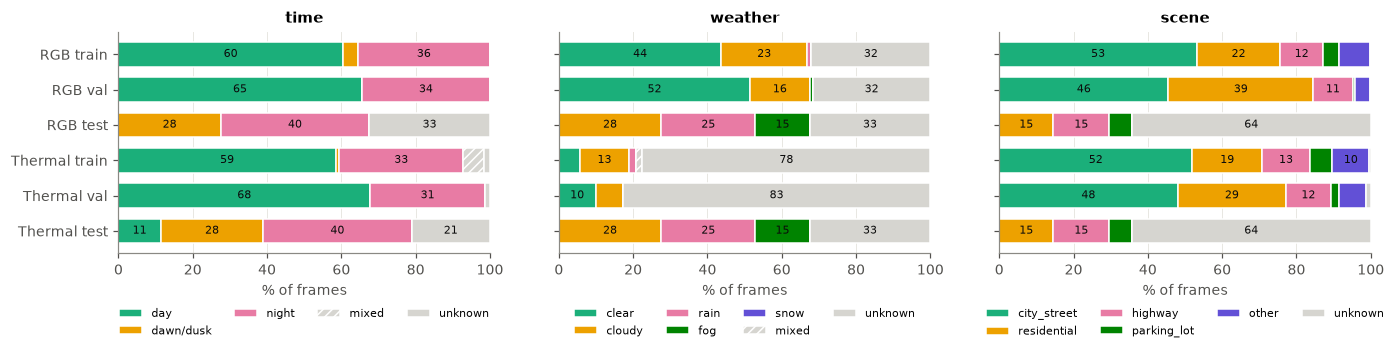

In [93]:
# Categorical slots 3-8 (slots 1-2 already mean RGB / thermal in this notebook).
DOMAIN_COLORS = ["#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
UNKNOWN_GRAY = "#d6d5d0"

ylabels = [f"{MOD_LABEL[m]} {s}" for m in MODS for s in SPLITS]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (f, cats) in zip(axes, FACETS.items()):
    y = np.arange(len(ylabels))[::-1]
    left = np.zeros(len(ylabels))
    series = [(c, DOMAIN_COLORS[i], None) for i, c in enumerate(cats)] + \
             [("mixed", UNKNOWN_GRAY, "////"), ("unknown", UNKNOWN_GRAY, None)]
    for c, color, hatch in series:
        share = np.array([100 * Counter(r[f][0] for r in domains[(m, s)])[c] / len(domains[(m, s)])
                          for m in MODS for s in SPLITS])
        if not share.any():
            continue
        ax.barh(y, share, left=left, height=0.7, color=color, hatch=hatch, label=c,
                edgecolor="white", linewidth=1)
        for yi, l, w in zip(y, left, share):
            if w >= 9:
                ax.text(l + w / 2, yi, f"{w:.0f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
        left += share
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of frames")
    ax.set_title(f"{f}")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=7.5)
axes[0].set_yticks(np.arange(len(ylabels))[::-1], ylabels)
fig.tight_layout()

for f, cats in FACETS.items():
    cols = cats + ["mixed", "unknown"]
    table([f"**{f}**: modality/split", *cols],
          [[f"{m}/{s}", *[Counter(r[f][0] for r in domains[(m, s)])[c] for c in cols]]
           for m in MODS for s in SPLITS])

### 8c. Test videos
The test split is the evaluation set for the domain-shift study, so its domains per video
(from video tags only). The RGB and thermal ids of one pair differ; pairs are matched in
`rgb_to_thermal_vid_map.json`.

In [94]:
for m in MODS:
    per_video = {q["video_id"]: q["n_frames"] for q in stats["sequences"][m]}
    vid_dom = {r["video_id"]: {f: r[f][0] for f in FACETS} for r in domains[(m, "test")]}
    table([f"{MOD_LABEL[m]} video_id", "frames", *FACETS],
          [[v, per_video.get(v), *[vid_dom[v][f] for f in FACETS]]
           for v in sorted(vid_dom, key=lambda v: -(per_video.get(v) or 0))])

| RGB video_id | frames | time | weather | scene |
|---|---|---|---|---|
| RMxN6a4CcCeLGu4tA | 1033 | dawn/dusk | cloudy | unknown |
| dvZBYnphN2BwdMKBc | 565 | unknown | unknown | highway |
| YnfPeH8i2uBWmsSd2 | 540 | night | rain | unknown |
| msNEBxJE5PPDqenBM | 428 | unknown | unknown | unknown |
| hnbGXq3nNPjBbc7CL | 411 | night | rain | unknown |
| BzZspxAweF8AnKhWK | 338 | night | fog | residential |
| FkqCGijjAKpABetZZ | 226 | unknown | unknown | parking_lot |
| PGdt7pJChnKoJDt35 | 208 | night | fog | residential |

| Thermal video_id | frames | time | weather | scene |
|---|---|---|---|---|
| ZAtDSNuZZjkZFvMAo | 1033 | dawn/dusk | cloudy | unknown |
| t3f7QC8hZr6zYXpEZ | 565 | unknown | unknown | highway |
| ePoikf5LyTTfqchga | 540 | night | rain | unknown |
| SCiKdG3MqZfiE292B | 428 | day | unknown | unknown |
| 5RSrbWYu9eokv5bvR | 411 | night | rain | unknown |
| 4FRnNpmSmwktFJKjg | 338 | night | fog | residential |
| 6tLtjdkv5K5BuhB37 | 226 | unknown | unknown | parking_lot |
| vbrSzr4vFTm5QwuGH | 208 | night | fog | residential |